# Financial Time-Series Analysis & Forecasting
*Project notebook, built from Assignment I*

**Project goal:** analyze financial time-series data using return transformations, rolling statistics, autocorrelation, and volatility analysis; implement ARIMA-based forecasting with rolling out-of-sample validation; and evaluate forecasts with standard error metrics.

**How this notebook teaches you:** every project step is tied to the homework problem that supplies its theory. Each section has a short *Concept* note, then code, then a *What to notice* note. Read the notes first, predict what the output will look like, then run the cell.

| Project step | Homework problems that give you the theory |
|---|---|
| Prices as random walks, return transformations | VII, VIII, IX (random walks), I (stationarity) |
| Rolling statistics (mean, variance) | X.1 (mean and variance), I (constant mean/variance) |
| Autocovariance, ACF, PACF, significance bands | II, III/IV (Bartlett CIs), V, X.2–X.3 |
| Model identification (AR / MA / ARMA) | V, VI, X.4 |
| Volatility analysis | I(f) (uncorrelated but not independent) |
| ARIMA forecasting + rolling validation + error metrics | V/VI/X (the models), then new material |

## 0. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from math import comb
from statsmodels.tsa.stattools import acf, pacf, acovf, adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 3.4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(2026)

## 1. Data
**Concept.** The project needs a financial price series. This sandbox has no internet access, so the notebook *simulates* a realistic daily price series (about 9 years of business days). It has the two features real stocks show: small returns and **volatility clustering** (calm periods and turbulent periods). The simulator is a GARCH(1,1) process, which you will meet again in Section 6.

**To use real data** (for example on your own machine), set `USE_REAL = True`. Everything after this cell works unchanged, because it only needs a `pd.Series` called `price`.

In [2]:
USE_REAL, TICKER = True, "SPY"          # flip to True on a machine with internet

if USE_REAL:
    import yfinance as yf
    price = yf.download(TICKER, start="2018-01-01", end="2026-08-01", auto_adjust=True)["Close"].squeeze().dropna()
else:
    n = 2200
    omega, alpha, beta, mu = 1e-6, 0.08, 0.90, 0.0004     # GARCH(1,1) parameters
    r = np.zeros(n); s2 = np.zeros(n); s2[0] = omega/(1-alpha-beta)
    z = rng.standard_t(6, n) / np.sqrt(6/4)               # fat-tailed shocks with unit variance
    for t in range(1, n):
        s2[t] = omega + alpha*(r[t-1]-mu)**2 + beta*s2[t-1]
        r[t] = mu + np.sqrt(s2[t])*z[t]
    idx = pd.bdate_range("2018-01-02", periods=n)
    price = pd.Series(100*np.exp(np.cumsum(r)), index=idx, name="price")

print(price.shape); price.head()

[*********************100%***********************]  1 of 1 completed

(2156,)


Date
2018-01-02    235.369766
2018-01-03    236.858551
2018-01-04    237.856827
2018-01-05    239.441986
2018-01-08    239.879837
Name: SPY, dtype: float64

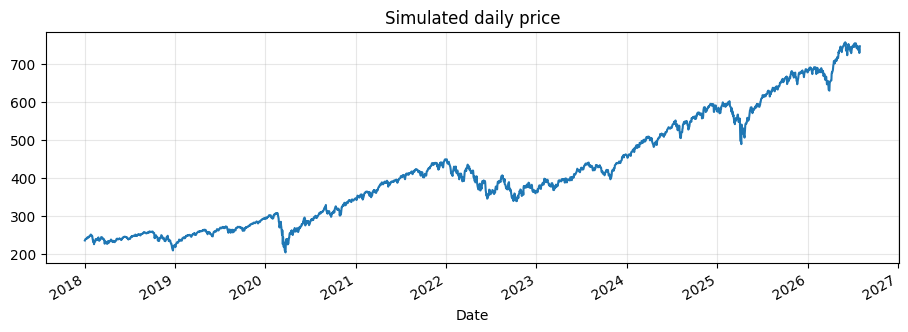

In [3]:
price.plot(title="Simulated daily price"); plt.show()

## 2. Prices behave like a random walk (Homework VII, VIII, IX)
**Concept.** In the homework, a simple random walk is $X_n = \xi_1+\dots+\xi_n$ with i.i.d. steps $\xi_i = \pm 1$. The three facts you proved all carry over to prices:

1. **Increments over disjoint time blocks are independent** (VIII-d: $X_4-X_2$ and $X_6-X_5$ are independent). This is why *past returns should say little about future returns*.
2. **The variance grows with time**, $\mathrm{Var}(X_n)=n$, so a random walk is **not stationary** (Problem I: stationarity needs constant mean and variance).
3. **Shifted pieces are again random walks** (VII-d: $Y_n=X_{5+n}-X_5$). Statistics computed on any window look alike.

The code checks fact 2 with the homework's own random walk, and then asks whether our price series is non-stationary.

In [4]:
# Simulate many symmetric random walks and check Var(X_n) = n   (Homework VII/VIII)
walks = np.cumsum(rng.choice([-1, 1], size=(20000, 100)), axis=1)
for n_ in (10, 50, 100):
    print(f"n={n_:3d}  empirical Var(X_n) = {walks[:, n_-1].var():7.2f}   theory = {n_}")

# Exact probabilities from Homework IX, checked by simulation
sim = np.cumsum(rng.choice([-1, 1], size=(200000, 16)), axis=1)      # columns are X_1..X_16
X = lambda k: sim[:, k-1]
print("\nIX-c  P[X7+X12 = X1+X16]  exact 63/256 =", round(63/256, 4), " simulated =", round(np.mean(X(7)+X(12)==X(1)+X(16)), 4))
print("IX-b  P[X9=3, X15=5]      exact 315/8192 =", round(315/8192, 4), " simulated =", round(np.mean((X(9)==3)&(X(15)==5)), 4))

n= 10  empirical Var(X_n) =   10.00   theory = 10
n= 50  empirical Var(X_n) =   49.62   theory = 50
n=100  empirical Var(X_n) =   99.41   theory = 100

IX-c  P[X7+X12 = X1+X16]  exact 63/256 = 0.2461  simulated = 0.2463
IX-b  P[X9=3, X15=5]      exact 315/8192 = 0.0385  simulated = 0.0382


ADF test on price: p-value = 0.992  -> cannot reject a unit root (non-stationary)


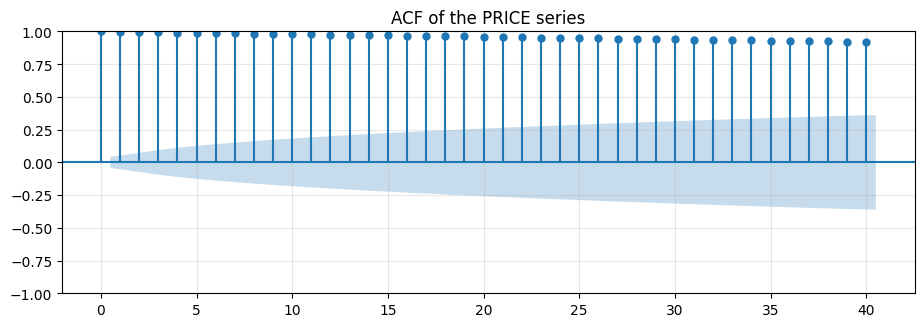

In [5]:
adf_p = adfuller(price)[1]
print(f"ADF test on price: p-value = {adf_p:.3f}  -> {'reject unit root (stationary)' if adf_p<0.05 else 'cannot reject a unit root (non-stationary)'}")
plot_acf(price, lags=40); plt.title("ACF of the PRICE series"); plt.show()

**What to notice.** The price ACF starts near 1 and decays very slowly. This is the classic fingerprint of a non-stationary, random-walk-like series. The ADF test (null hypothesis: unit root) agrees. We cannot fit stationary ARMA models to prices directly. We must transform them first, which is the next section.

## 3. Return transformations (Homework I)
**Concept.** Differencing a random walk gives back its i.i.d. steps: $X_n - X_{n-1}=\xi_n$. For prices the analogue is the **return**:

- **Simple return:** $R_t = \dfrac{P_t - P_{t-1}}{P_{t-1}}$
- **Log return:** $r_t = \ln P_t - \ln P_{t-1}$

Log returns are preferred in time-series work because they **add across time** ($r_{t\to t+k}=\sum r$, just like the sum of steps in a random walk) and are close to simple returns when returns are small. In ARIMA language, taking a log and then differencing once is exactly the "I(1)" part: **ARIMA(p,1,q) on log price = ARMA(p,q) on log returns**.

           simple         log
count  2155.00000  2155.00000
mean      0.00061     0.00053
std       0.01205     0.01208
min      -0.10942    -0.11589
25%      -0.00428    -0.00429
50%       0.00090     0.00090
75%       0.00653     0.00651
max       0.10502     0.09986

max |simple - log| = 0.00646
ADF test on log returns: p-value = 2.44e-27  (small -> stationary)


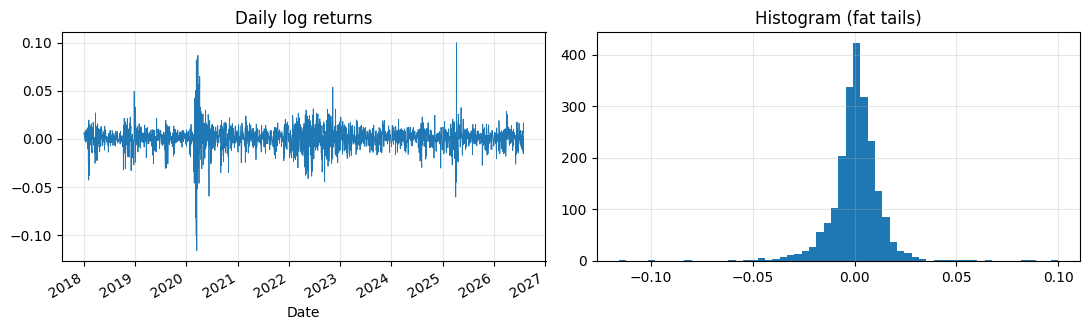

In [6]:
log_price = np.log(price)
simple_ret = price.pct_change().dropna()
log_ret = log_price.diff().dropna()

print(pd.DataFrame({"simple": simple_ret.describe(), "log": log_ret.describe()}).round(5))
print("\nmax |simple - log| =", float((simple_ret - log_ret).abs().max()).__round__(5))
print(f"ADF test on log returns: p-value = {adfuller(log_ret)[1]:.2e}  (small -> stationary)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
log_ret.plot(ax=ax[0], lw=.6, title="Daily log returns"); log_ret.hist(bins=60, ax=ax[1]); ax[1].set_title("Histogram (fat tails)")
plt.tight_layout(); plt.show()

**What to notice.** The returns hover around zero with no trend. The ADF test now rejects the unit root, so we have a **stationary** series (Problem I: constant mean, constant variance, autocovariance depends only on the lag). The histogram has fatter tails than a normal distribution, a common feature of financial returns.

## 4. Rolling statistics (Homework X.1, Problem I)
**Concept.** A stationary process has a constant mean and variance. Problem X.1 asked for one mean and one variance for the whole sample. A **rolling** mean and standard deviation compute those same quantities over a sliding window (for example 21 trading days, about one month). If the series were really stationary with constant variance, the rolling lines would be flat apart from noise. We **annualize** volatility by multiplying a daily standard deviation by $\sqrt{252}$, because variances of i.i.d. daily returns add across days.

Whole-sample mean = 0.00053,  variance = 0.000146,  daily std = 0.0121


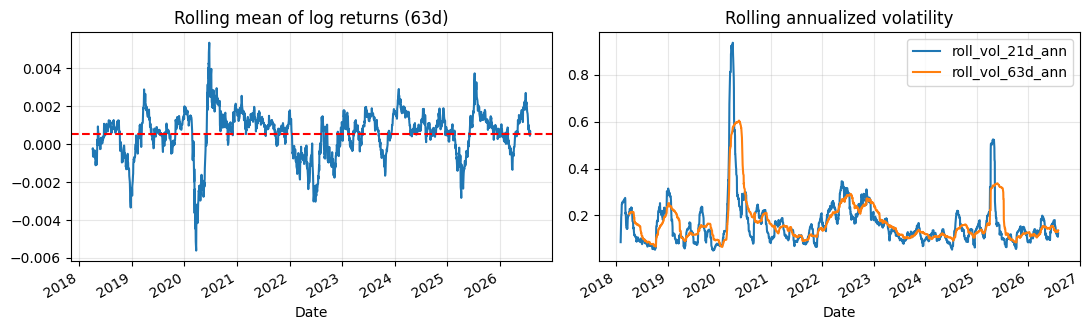

In [7]:
full_mean, full_var = log_ret.mean(), log_ret.var(ddof=1)     # same recipe as Problem X.1
print(f"Whole-sample mean = {full_mean:.5f},  variance = {full_var:.6f},  daily std = {np.sqrt(full_var):.4f}")

roll = pd.DataFrame({"roll_mean_63d": log_ret.rolling(63).mean(),
                     "roll_vol_21d_ann": log_ret.rolling(21).std()*np.sqrt(252),
                     "roll_vol_63d_ann": log_ret.rolling(63).std()*np.sqrt(252)})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
roll["roll_mean_63d"].plot(ax=ax[0], title="Rolling mean of log returns (63d)"); ax[0].axhline(full_mean, color="r", ls="--")
roll[["roll_vol_21d_ann", "roll_vol_63d_ann"]].plot(ax=ax[1], title="Rolling annualized volatility")
plt.tight_layout(); plt.show()

**What to notice.** The rolling *mean* wobbles around a small constant. The rolling *volatility* clearly rises and falls: the mean is stable but the variance is not constant. So returns are close to stationary in the mean, but their spread changes through time. Section 6 studies this.

## 5. Autocovariance, ACF and PACF (Homework II, III/IV, V, X.2–X.3)
**Concept.**
- **ACVF** $\hat\gamma(k)=\frac1n\sum_{t=1}^{n-k}(x_t-\bar x)(x_{t+k}-\bar x)$ and **ACF** $\hat\rho(k)=\hat\gamma(k)/\hat\gamma(0)$ measure linear dependence at lag $k$. (Problem X.2 asked for exactly these.)
- **PACF** $\phi_{kk}$ is the correlation at lag $k$ *after removing the effect of lags 1..k-1*. It is computed with the Durbin–Levinson recursion you used in Problem V(c).
- **Significance band:** for white noise, $\hat\rho(k)\approx N(0,1/n)$, so about 95% of values lie inside $\pm1.96/\sqrt n$. This is the dashed band in all your plots.
- **Bartlett intervals (Problem III/IV):** if you assume a specific model, the variance of $\hat\rho(k)$ changes. For MA(1): $\mathrm{Var}\,\hat\rho(1)\approx(1-3\rho^2+4\rho^4)/n$. For AR(1): $\mathrm{Var}\,\hat\rho(1)\approx(1-\phi^2)/n$.
- **Ljung–Box test:** one joint test that *all* autocorrelations up to lag $m$ are zero. A small p-value means the series is not white noise.

We first write the tools from scratch, so you see there is no magic, and verify them against `statsmodels`.

In [8]:
def acvf_manual(x, K=20):
    x = np.asarray(x, float); n = len(x); xc = x - x.mean()
    return np.array([np.sum(xc[:n-k]*xc[k:])/n for k in range(K+1)])

def durbin_levinson(rho, K):
    # PACF from ACF values rho[0..K]  (the recursion used in Homework V(c))
    phi = np.zeros((K+1, K+1)); out = [rho[1]]; phi[1, 1] = rho[1]
    for k in range(2, K+1):
        num = rho[k] - sum(phi[k-1, j]*rho[k-j] for j in range(1, k))
        den = 1 - sum(phi[k-1, j]*rho[j] for j in range(1, k))
        phi[k, k] = num/den
        for j in range(1, k): phi[k, j] = phi[k-1, j] - phi[k, k]*phi[k-1, k-j]
        out.append(phi[k, k])
    return np.array(out)

def bartlett_ci(r1, r2, n, model, phi=None, z=1.96):
    # Approximate CIs for rho(1), rho(2)  (Homework III/IV)
    if model == "AR1":
        p = phi if phi is not None else r1
        v1 = (1-p**2)/n;  v2 = ((1+p**2)*(1-p**4)/(1-p**2) - 4*p**4)/n
    else:  # MA1
        v1 = (1-3*r1**2+4*r1**4)/n;  v2 = (1+2*r1**2)/n
    return (r1-z*v1**.5, r1+z*v1**.5), (r2-z*v2**.5, r2+z*v2**.5)

# Check the tools against statsmodels on the log returns
g = acvf_manual(log_ret, 20); rho = g/g[0]
print("ACF matches statsmodels :", np.allclose(rho, acf(log_ret, nlags=20, fft=False)))
print("PACF matches statsmodels:", np.allclose(durbin_levinson(rho, 20), pacf(log_ret, nlags=20, method="ywm")[1:]))
# Reproduce Homework III/IV
print("\nHomework III(a) AR(1) CIs:", [tuple(np.round(c, 3)) for c in bartlett_ci(.438, .145, 100, "AR1")])
print("Homework III(b) MA(1) CIs:", [tuple(np.round(c, 3)) for c in bartlett_ci(.438, .145, 100, "MA1")])

ACF matches statsmodels : True
PACF matches statsmodels: True

Homework III(a) AR(1) CIs: [(np.float64(0.262), np.float64(0.614)), (np.float64(-0.076), np.float64(0.366))]
Homework III(b) MA(1) CIs: [(np.float64(0.29), np.float64(0.586)), (np.float64(-0.086), np.float64(0.376))]


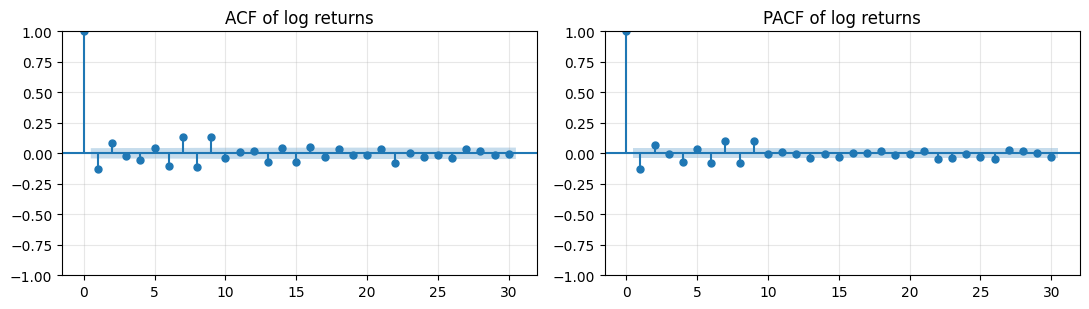

95% white-noise band = +/-0.042;  largest |ACF| over lags 1-20 = 0.132 (lag 1)
     lb_stat  lb_pvalue
5    66.1333        0.0
10  192.2835        0.0
20  231.3207        0.0


In [9]:
def acf_pacf_plot(x, lags=30, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    plot_acf(x, lags=lags, ax=ax[0], title=f"ACF {title}"); plot_pacf(x, lags=lags, ax=ax[1], method="ywm", title=f"PACF {title}")
    plt.tight_layout(); plt.show()

acf_pacf_plot(log_ret, title="of log returns")
band = 1.96/np.sqrt(len(log_ret))
lb = acorr_ljungbox(log_ret, lags=[5, 10, 20])
a20 = acf(log_ret, nlags=20, fft=False)[1:]
print(f"95% white-noise band = +/-{band:.3f};  largest |ACF| over lags 1-20 = {np.abs(a20).max():.3f} (lag {np.abs(a20).argmax()+1})")
print(lb.round(4))

**What to notice.** Almost all ACF/PACF bars sit inside or barely outside the band, and the largest autocorrelation is tiny (even a correlation of 0.08 explains under 1% of the variance). The Ljung–Box test may still reject at some lags. Do **not** over-read that: the test assumes constant variance, and our returns have volatility clustering (Section 6), which makes the test reject too easily. The practical conclusion is that daily returns are **nearly uncorrelated**, as random-walk theory (independent increments) predicts. That is why returns are hard to forecast, and why the project evaluates ARIMA *out of sample* instead of trusting in-sample fit.

## 6. Volatility analysis (Homework I-f)
**Concept.** Problem I(f) showed that $X_t=Z_tZ_{t-1}$ is **white noise (uncorrelated) but not independent**. Financial returns behave the same way: returns are uncorrelated, but their *size* is predictable. Large moves follow large moves (**volatility clustering**). The diagnostic is to compute the ACF of the **squared** (or absolute) returns. If squared returns have strong autocorrelation, the variance changes over time and the series has *conditional heteroskedasticity* (ARCH/GARCH effects).

We also build an **EWMA volatility**, $\sigma_t^2=\lambda\sigma_{t-1}^2+(1-\lambda)r_{t-1}^2$ with $\lambda=0.94$ (the RiskMetrics value). It is a simple forecast of tomorrow's variance.

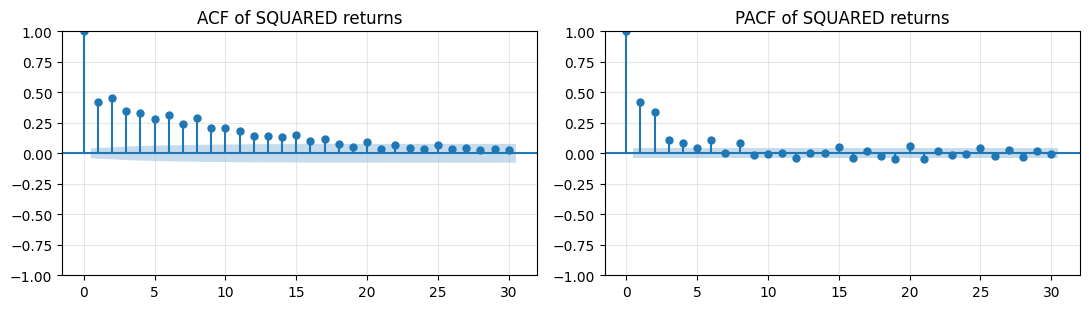

Ljung-Box on squared returns:
      lb_stat  lb_pvalue
5   1485.7330        0.0
10  2186.6758        0.0
20  2521.0842        0.0


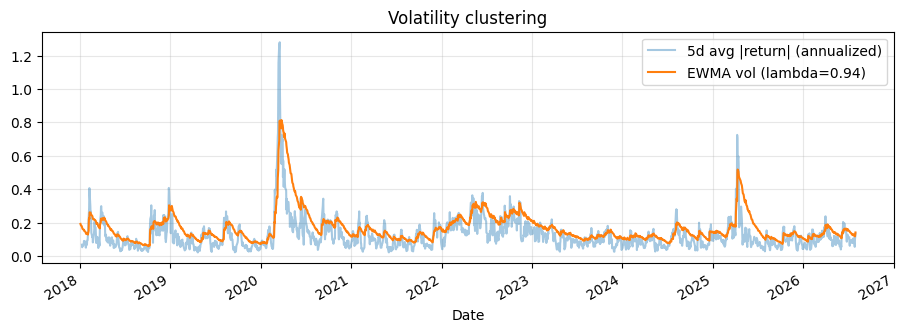

In [10]:
acf_pacf_plot(log_ret**2, title="of SQUARED returns")
print("Ljung-Box on squared returns:"); print(acorr_ljungbox(log_ret**2, lags=[5, 10, 20]).round(4))

lam = 0.94
ewma_var = np.zeros(len(log_ret)); ewma_var[0] = log_ret.var()
for t in range(1, len(log_ret)): ewma_var[t] = lam*ewma_var[t-1] + (1-lam)*log_ret.iloc[t-1]**2
ewma_vol = pd.Series(np.sqrt(ewma_var*252), index=log_ret.index)
ax = (log_ret.abs()*np.sqrt(252)).rolling(5).mean().plot(alpha=.4, label="5d avg |return| (annualized)")
ewma_vol.plot(ax=ax, label="EWMA vol (lambda=0.94)"); ax.legend(); ax.set_title("Volatility clustering"); plt.show()

**What to notice.** Returns have no autocorrelation, but the **squared returns** show strongly significant autocorrelation, and the Ljung–Box test rejects. This is the key lesson: **ARIMA models the conditional mean** (the level of returns), and cannot capture this volatility structure. For that you would add a GARCH model. In this project, volatility analysis tells us *how much uncertainty* surrounds the forecasts, not *which direction* the market goes.

## 7. Model identification: practice on known models (Homework V, VI, X.4)
**Concept.** Before trusting ARIMA on real data, check that you can read the plots. The identification rules are:

| Process | ACF | PACF |
|---|---|---|
| MA(q) | **cuts off** after lag q | tails off |
| AR(p) | tails off | **cuts off** after lag p |
| ARMA(p,q) | tails off | tails off |

You simulated an MA(2) (Problem V) and an ARMA(1,1) (Problem VI). Below are the same simulations, plus the Recruitment series from Problem X, which looked like an AR(2).

Theory rho(1), rho(2) = [-0.6691  0.1859] (from Problem V(a))


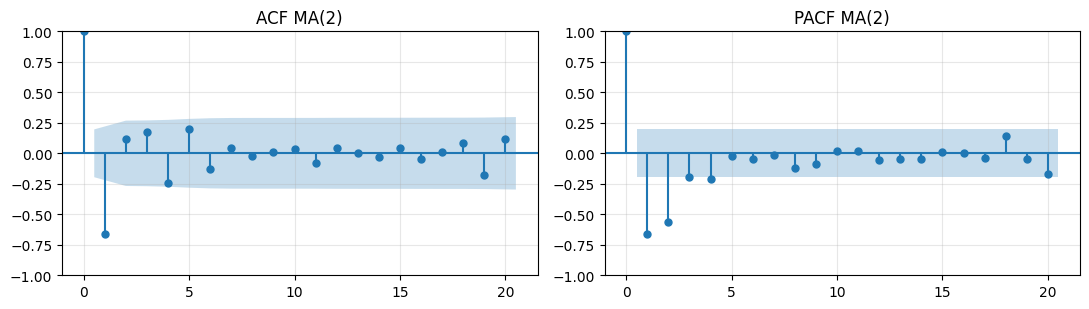

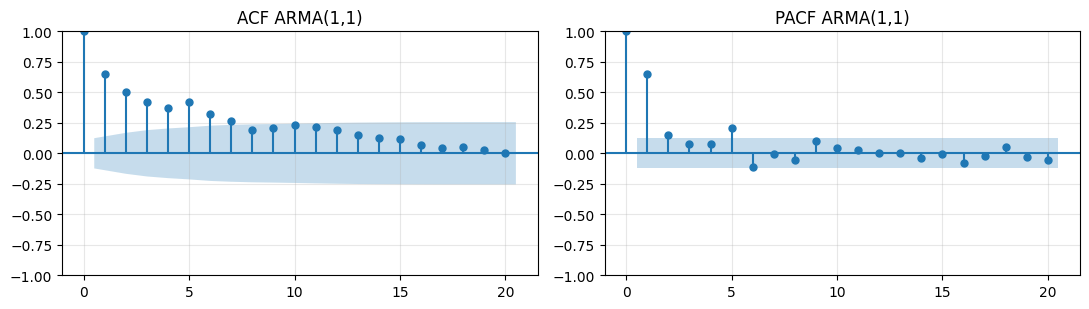

In [11]:
# Problem V: MA(2),  Z_t = (1 - 1.2B + 0.5B^2) a_t,   n = 100
a = rng.normal(0, 1, 102); ma2 = a[2:] - 1.2*a[1:-1] + 0.5*a[:-2]
th = np.array([1, -1.2, .5]); g = [th[:3-k] @ th[k:] for k in range(3)]
print("Theory rho(1), rho(2) =", np.round([g[1]/g[0], g[2]/g[0]], 4), "(from Problem V(a))")
acf_pacf_plot(ma2, 20, "MA(2)")

# Problem VI: ARMA(1,1),  (1-0.9B) Z_t = (1-0.5B) a_t,   n = 250
e = rng.normal(0, 1, 450); arma = np.zeros(450)
for t in range(1, 450): arma[t] = .9*arma[t-1] + e[t] - .5*e[t-1]
arma = arma[200:]; acf_pacf_plot(arma, 20, "ARMA(1,1)")

Recruitment: n=100, mean=51.05, variance=735.7


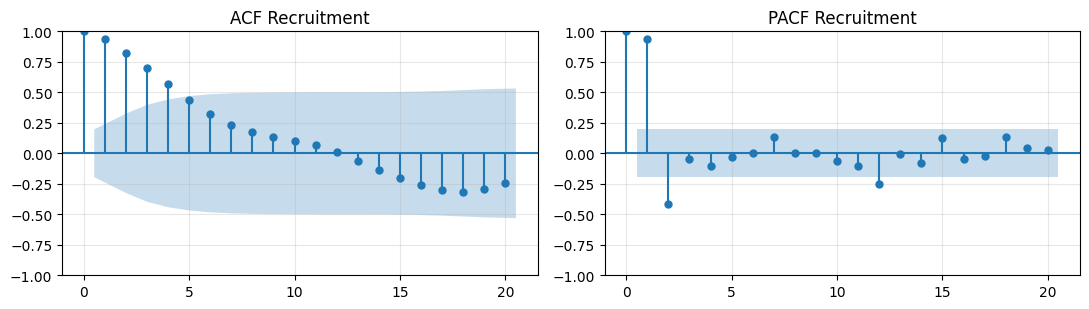

In [12]:
# Problem X: the Recruitment series (the 100 values printed in the assignment)
rec = np.array("""68.63 68.63 68.63 68.63 68.63 68.63 59.16 48.70 47.54 50.91 44.70 42.85 39.62 44.45 38.98 42.62
48.27 59.39 51.66 38.55 60.33 72.27 68.62 69.63 72.20 67.87 64.91 53.85 37.96 23.23 12.68 9.84
7.82 11.78 10.22 12.19 18.60 26.97 22.52 19.18 17.14 18.61 20.02 22.65 38.99 76.55 87.99 99.80
96.69 87.45 88.57 97.43 99.99 94.88 86.99 79.73 92.35 91.29 94.31 84.95 82.97 92.98 81.06 62.37
52.99 39.53 42.90 33.76 40.97 60.50 66.61 80.38 95.86 97.74 80.24 73.44 65.67 47.81 33.51 34.22
32.95 32.55 46.92 44.64 53.02 41.98 30.43 24.43 18.05 20.98 12.37 12.03 12.41 15.89 20.46 26.95
30.29 26.21 23.34 25.55""".split(), float)
print(f"Recruitment: n={len(rec)}, mean={rec.mean():.2f}, variance={rec.var(ddof=1):.1f}")
acf_pacf_plot(rec, 20, "Recruitment")

**What to notice.** MA(2): ACF cuts off at lag 2, PACF tails off. ARMA(1,1): both tail off, with a slowly decaying ACF. Recruitment: the ACF decays like a damped wave and the PACF cuts off after lag 2, which suggests an **AR(2)** (what you found in Problem X). Unlike the stock returns of Section 5, **Recruitment has strong autocorrelation**, so it is a series where ARIMA should really help. We use it in Section 10 as a contrast.

## 8. Fitting ARIMA and choosing the order
**Concept.** `ARIMA(p, d, q)` has three parts: AR order $p$, differencing order $d$ (what we did in Section 3), and MA order $q$. Since we model log *returns* (already differenced), we use $d=0$. Candidate orders are compared with **AIC**, $2k-2\ln L$, which rewards fit but penalizes extra parameters. Lower is better. **Important:** choose the order using the **training** data only. Using the test data would be look-ahead bias (cheating).

In [13]:
split = int(len(log_ret)*0.8)
train, test = log_ret.iloc[:split], log_ret.iloc[split:]
print(f"train: {len(train)} days ({train.index[0].date()} to {train.index[-1].date()}),  test: {len(test)} days")

def aic_grid(y, pmax=3, qmax=3, d=0):
    rows = []
    for p in range(pmax+1):
        for q in range(qmax+1):
            try: rows.append((p, d, q, ARIMA(np.asarray(y), order=(p, d, q)).fit().aic))
            except Exception: pass
    return pd.DataFrame(rows, columns=["p", "d", "q", "AIC"]).sort_values("AIC").reset_index(drop=True)

grid = aic_grid(train); print(grid.head(6).round(2))
best = tuple(grid.loc[0, ["p", "d", "q"]].astype(int)); print("\nSelected order:", best)
res = ARIMA(np.asarray(train), order=best).fit(); print(res.summary().tables[1])

train: 1724 days (2018-01-03 to 2024-11-07),  test: 431 days
   p  d  q       AIC
0  0  0  2 -10283.29
1  2  0  0 -10282.60
2  0  0  3 -10282.13
3  3  0  0 -10280.93
4  2  0  1 -10280.40
5  1  0  3 -10280.01

Selected order: (0, 0, 2)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.000      1.707      0.088   -7.77e-05       0.001
ma.L1         -0.1250      0.011    -11.148      0.000      -0.147      -0.103
ma.L2          0.0859      0.010      8.879      0.000       0.067       0.105
sigma2         0.0001   2.16e-06     69.147      0.000       0.000       0.000


**What to notice.** Look at the AIC column: the top candidates are within a few AIC points of each other, which is a weak preference. If the chosen model mixes AR and MA terms of similar size and opposite sign (for example AR1 ≈ +0.7 with MA1 ≈ −0.7), they largely *cancel* each other. That is a warning sign of an over-parameterized model chasing a tiny pattern, and a reason to prefer a simpler order when AICs are close (parsimony). Significant coefficients *in sample* do not prove the model forecasts better. Whether even the "best" ARIMA beats a trivial benchmark is what **rolling out-of-sample validation** answers.

## 9. Rolling out-of-sample validation and error metrics
**Concept.** One train/test split gives one noisy verdict. **Rolling (walk-forward) validation** imitates real forecasting:

1. Take the most recent `window` observations up to day $t$.
2. Fit (or reuse recently fitted parameters on the updated data) and forecast **one step ahead**, day $t+1$.
3. Move forward one day, reveal the true value, and repeat.

To keep it fast we **refit** the parameters every `refit_every` days, and in between only update the *data* the model filters through (parameters held fixed). No forecast ever uses information from its own future.

**Benchmarks matter.** A forecast error number means nothing alone. We compare with two naive forecasters: **zero** (predict "no change", the random-walk forecast) and **historical mean** of the window.

**Error metrics:**
- **MAE** $=\frac1m\sum|e_t|$ (average miss, in return units) and **RMSE** $=\sqrt{\frac1m\sum e_t^2}$ (penalizes big misses).
- **MAPE** $=\frac{100}{m}\sum|e_t/y_t|$. It is unstable for returns (since $y_t\approx0$), so we report it on the **price level**, where it is meaningful.
- **Relative RMSE** $=\mathrm{RMSE}_{model}/\mathrm{RMSE}_{benchmark}$. Below 1 means the model beats the benchmark.
- **Directional accuracy:** fraction of days where the forecast has the right sign. 50% is coin-flipping.

In [14]:
def rolling_arima(y, order, window, start, refit_every=21):
    # One-step-ahead rolling forecasts of y[start:], using only data BEFORE each forecast date
    y = np.asarray(y, float); preds = []; res = None
    for i in range(start, len(y)):
        if res is None or (i - start) % refit_every == 0:
            res = ARIMA(y[i-window:i], order=order).fit()           # refit on the latest window
        # keep fitted parameters, update the data through day i-1, forecast day i
        preds.append(float(res.apply(y[i-window:i], refit=False).forecast(1)[0]))
    return np.array(preds)

def rolling_mean_bench(y, window, start):
    y = np.asarray(y, float); return np.array([y[i-window:i].mean() for i in range(start, len(y))])

def metrics(actual, pred, name, prev=0.0):
    # prev = reference level for "direction": 0 for returns (sign of the return),
    # or yesterday's value for a level series (sign of the change)
    e = actual - pred
    d = np.mean(np.sign(actual - prev) == np.sign(pred - prev)) if np.any(pred != prev) else np.nan
    return {"model": name, "MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)), "Dir. acc.": d}

WINDOW = 750
start = split
y = log_ret.values
pred_arima = rolling_arima(y, best, WINDOW, start)
pred_zero  = np.zeros(len(y)-start)
pred_mean  = rolling_mean_bench(y, WINDOW, start)
actual = y[start:]

tab = pd.DataFrame([metrics(actual, pred_arima, f"ARIMA{best}"), metrics(actual, pred_zero, "Zero (random walk)"), metrics(actual, pred_mean, "Rolling mean")]).set_index("model")
tab["Rel. RMSE vs zero"] = tab["RMSE"]/tab.loc["Zero (random walk)", "RMSE"]
print(tab.round(5))

                        MAE     RMSE  Dir. acc.  Rel. RMSE vs zero
model                                                             
ARIMA(0, 0, 2)      0.00700  0.01081    0.54060            1.00185
Zero (random walk)  0.00701  0.01079        NaN            1.00000
Rolling mean        0.00695  0.01077    0.56148            0.99881


                    Price MAE  Price RMSE  MAPE %
model                                            
ARIMA(0, 0, 2)         4.3747      6.3889  0.7002
Zero (random walk)     4.3802      6.3790  0.7007
Rolling mean           4.3462      6.3705  0.6957


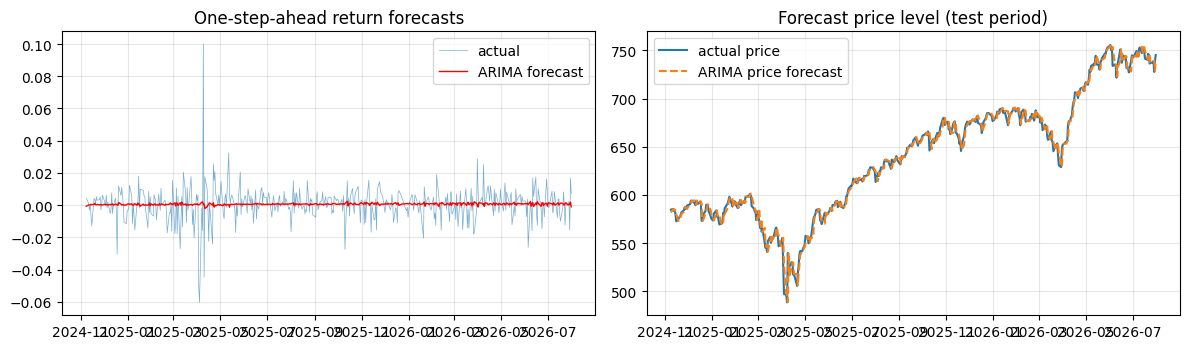

In [15]:
# Convert return forecasts to PRICE forecasts so MAPE is meaningful:  P_hat(t) = P(t-1) * exp(r_hat(t))
prev_price = price.shift(1).reindex(log_ret.index).values[start:]
true_price = price.reindex(log_ret.index).values[start:]
rows = []
for name, p in [(f"ARIMA{best}", pred_arima), ("Zero (random walk)", pred_zero), ("Rolling mean", pred_mean)]:
    ph = prev_price*np.exp(p); rows.append({"model": name, "Price MAE": np.mean(np.abs(true_price-ph)), "Price RMSE": np.sqrt(np.mean((true_price-ph)**2)), "MAPE %": 100*np.mean(np.abs((true_price-ph)/true_price))})
print(pd.DataFrame(rows).set_index("model").round(4))

idx_t = log_ret.index[start:]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(idx_t, actual, lw=.5, label="actual", alpha=.6); ax[0].plot(idx_t, pred_arima, color="r", lw=1, label="ARIMA forecast"); ax[0].legend(); ax[0].set_title("One-step-ahead return forecasts")
ax[1].plot(idx_t, true_price, label="actual price"); ax[1].plot(idx_t, prev_price*np.exp(pred_arima), "--", label="ARIMA price forecast"); ax[1].legend(); ax[1].set_title("Forecast price level (test period)")
plt.tight_layout(); plt.show()

**What to notice.** The ARIMA forecast line is tiny compared with the actual returns, so RMSE is essentially the same as the benchmarks: the relative RMSE is about 1 (a value slightly *above* 1 means ARIMA did marginally **worse** than predicting zero). The directional accuracy above 50% is mostly the positive drift of this series (more up days than down days): the "rolling mean" benchmark, which only knows the average drift, scores about the same. So the ARIMA structure adds nothing measurable here. On the **price level** the MAPE looks tiny, but that is misleading: any forecast of "tomorrow's price is about today's price" has a tiny MAPE, because prices barely move in one day. This is why you judge a model against a **benchmark** and not by its MAPE alone. The honest conclusion is that ARIMA adds little to *daily* returns, which matches Sections 2 and 5.

**Residual check (always do this):** if the model captured everything linear, the residuals should look like white noise. The next cell checks that, and also shows what ARIMA *cannot* fix (volatility clustering).

In [16]:
resid = pd.Series(res.resid)
print("Ljung-Box on residuals        :", acorr_ljungbox(resid, lags=[10])["lb_pvalue"].iloc[0].round(4), "(large -> no leftover linear structure)")
print("Ljung-Box on squared residuals:", acorr_ljungbox(resid**2, lags=[10])["lb_pvalue"].iloc[0].round(6), "(small -> volatility clustering remains)")

Ljung-Box on residuals        : 0.0 (large -> no leftover linear structure)
Ljung-Box on squared residuals: 0.0 (small -> volatility clustering remains)


## 10. Contrast: the same workflow where ARIMA *does* work (Recruitment, Homework X)
**Concept.** Section 9 showed ARIMA struggling on returns because returns are nearly unpredictable. The Recruitment series, with its strong ACF and a PACF that cuts off at lag 2, is the opposite case. We run the *same* rolling out-of-sample pipeline: AR(2), a fixed window, a naive benchmark, and the same metrics. For a series that wanders around a level, the natural naive benchmark is the **last value** ("persistence").

                             MAE    RMSE  Dir. acc.  Rel. RMSE vs persistence  \
model                                                                           
AR(2) rolling              7.051   8.489      0.600                     0.893   
Last value (persistence)   7.696   9.506        NaN                     1.000   
Window mean               26.176  29.371      0.525                     3.090   

                          MAPE %  
model                             
AR(2) rolling             18.650  
Last value (persistence)  18.747  
Window mean               98.334  


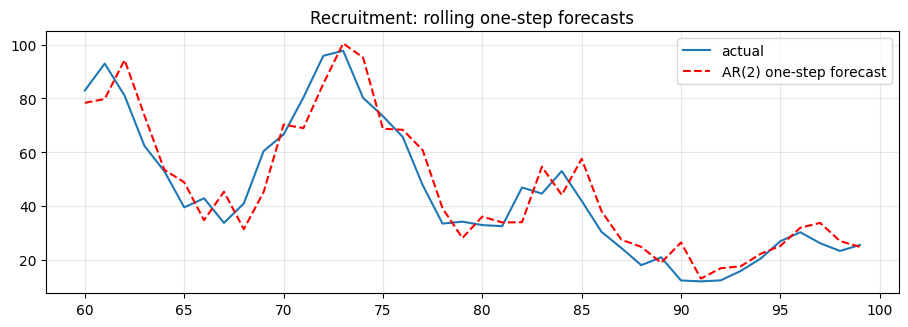

In [17]:
W = 50; st = 60
pred_ar2 = rolling_arima(rec, (2, 0, 0), W, st, refit_every=5)
pred_last = rec[st-1:-1]                          # yesterday's value
pred_m = np.array([rec[i-W:i].mean() for i in range(st, len(rec))])
act = rec[st:]
prev = rec[st-1:-1]                                # yesterday's value, to judge the direction of change
out = pd.DataFrame([metrics(act, pred_ar2, "AR(2) rolling", prev), metrics(act, pred_last, "Last value (persistence)", prev), metrics(act, pred_m, "Window mean", prev)]).set_index("model")
out["Rel. RMSE vs persistence"] = out["RMSE"]/out.loc["Last value (persistence)", "RMSE"]
out["MAPE %"] = [100*np.mean(np.abs((act-p)/act)) for p in (pred_ar2, pred_last, pred_m)]
print(out.round(3))
plt.plot(range(st, len(rec)), act, label="actual"); plt.plot(range(st, len(rec)), pred_ar2, "r--", label="AR(2) one-step forecast"); plt.legend(); plt.title("Recruitment: rolling one-step forecasts"); plt.show()

**What to notice.** Here AR(2) beats both benchmarks: its RMSE is about 11% lower than persistence (relative RMSE below 1), and far lower than the window mean, which ignores the strong short-term dependence. The gain over persistence is modest in MAPE (the series is so persistent that "same as yesterday" is already hard to beat), but it is consistent, and it happens because the series has real, exploitable autocorrelation, which is what the ACF/PACF identification of Section 7 predicted. Direction is now measured as the sign of the *change* from yesterday, since the Recruitment values are always positive. This is the central message of the whole project: **the ACF/PACF diagnostics tell you in advance whether ARIMA can help.** Returns: no (but squared returns say volatility is predictable). Recruitment: yes.

## 11. Summary: how the homework became the project

1. **Random walks (VII–IX)** explain why prices are non-stationary and returns are nearly unpredictable.
2. **Stationarity (I)** is why we model returns, check with ADF, and use rolling mean/variance.
3. **ACVF, ACF, PACF, Bartlett bands (II, III/IV, V, X)** are the identification toolkit, and you coded all of it from scratch.
4. **Model patterns (V, VI, X.4)** (MA cuts off in the ACF, AR cuts off in the PACF) tell you which ARIMA orders to try.
5. **Uncorrelated is not independent (I-f)** leads to the volatility analysis (ACF of squared returns, EWMA).
6. **Rolling out-of-sample validation + MAE/RMSE/MAPE/directional accuracy + a benchmark** is how you honestly evaluate a forecast.

**Suggested resume bullet (matches what this notebook really does):** *Analyzed financial time-series using log-return transformations, rolling statistics, ACF/PACF and volatility-clustering diagnostics (Ljung–Box, EWMA); built ARIMA models selected by AIC and evaluated them with walk-forward one-step-ahead validation against naive benchmarks using MAE, RMSE, MAPE and directional accuracy.*

**Exercises to try next**
- Set `USE_REAL = True` and rerun with a real ticker. Do the squared-return ACFs still show clustering? Does ARIMA beat the zero forecast?
- Change `WINDOW` (250, 500, 1000) and `refit_every`. How stable is the relative RMSE?
- Weekly returns (`price.resample("W").last()`) can show more autocorrelation than daily ones. Test it with Ljung–Box.
- Add a GARCH(1,1) model (`pip install arch`) to forecast volatility, and compare it with EWMA.